# Tópicos de Big Data —
## Examen práctico · Versión A

**Tiempo máximo: 90 minutos**  
**Calificación de este : 100 puntos (escala de 0 a 100)**  
**Nombre:** Leonel Alessandro González Martínez  
**Grupo:** 511  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

> **Nota sobre el dataset.** El archivo que recibí traía la columna `payment_type` con números del 1 al 4. Antes de empezar cambié esos números por su etiqueta según el diccionario de datos de la NYC TLC: 1 es Credit card, 2 es Cash, 3 es No charge y 4 es Dispute. El resultado lo guardé como `data/raw/nyc_taxi_examen.csv`. No cambié ninguna otra columna ni borré registros. La limpieza se hace en la sección 2.

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

print("Primeras cinco filas:")
display(df.head())

print(f"Dimensiones (filas, columnas): {df.shape}")

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nResumen estadístico de las columnas numéricas:")
display(df.describe().T.round(2))

print("Valores en la columna payment_type:")
print(df["payment_type"].value_counts(dropna=False))

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones (filas, columnas): (2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type                 str
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport

,count,mean,std,min,25%,50%,75%,max
VendorID,2427612.0,1.89,0.81,1.00,2.00,2.00,2.00,7.00
passenger_count,2415489.0,1.30,1.88,-5.00,1.00,1.00,1.00,100.00
trip_distance,2415470.0,3.30,5.17,-99.99,0.99,1.70,3.36,1686.49
RatecodeID,2415474.0,4.23,17.20,1.00,1.00,1.00,1.00,99.00
PULocationID,2415487.0,164.14,62.85,1.00,132.00,161.00,232.00,265.00
DOLocationID,2415475.0,163.22,69.26,1.00,113.00,162.00,234.00,265.00
fare_amount,2415488.0,38.53,542.38,-1849.60,9.30,13.50,21.90,19995.59
extra,2415487.0,1.57,1.91,-7.50,0.00,1.00,2.50,23.25
mta_tax,2415462.0,0.48,0.10,-0.50,0.50,0.50,0.50,11.50
tip_amount,2415459.0,3.67,4.23,-90.00,1.00,2.95,4.56,444.44


Valores en la columna payment_type:
payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [2]:
df_limpio = df.copy()

print("Dimensiones antes de limpiar:", df_limpio.shape)
print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())
print("\nTotal de celdas nulas:", df_limpio.isnull().sum().sum())
print("Filas con al menos un nulo:", df_limpio.isnull().any(axis=1).sum())
print("Registros duplicados:", df_limpio.duplicated().sum())

filas = len(df_limpio)
df_limpio = df_limpio.drop_duplicates()
print(f"\nDespués de eliminar duplicados: {df_limpio.shape}  (se quitaron {filas - len(df_limpio):,})")

filas = len(df_limpio)
df_limpio = df_limpio.dropna()
print(f"Después de eliminar nulos:      {df_limpio.shape}  (se quitaron {filas - len(df_limpio):,})")

condiciones = {
    "trip_distance > 0":        df_limpio["trip_distance"] > 0,
    "passenger_count > 0":      df_limpio["passenger_count"] > 0,
    "passenger_count < 100":    df_limpio["passenger_count"] < 100,
    "fare_amount > 0":          df_limpio["fare_amount"] > 0,
    "fare_amount < 10000":      df_limpio["fare_amount"] < 10000,
    "trip_duration > 0":        df_limpio["trip_duration"] > 0,
}
print("\nRegistros que NO cumplen cada condición:")
for nombre, cumple in condiciones.items():
    print(f"  {nombre:<24} {(~cumple).sum():>8,}")

filtro = np.logical_and.reduce(list(condiciones.values()))
filas = len(df_limpio)
df_limpio = df_limpio[filtro].reset_index(drop=True)
print(f"\nDespués de aplicar condiciones: {df_limpio.shape}  (se quitaron {filas - len(df_limpio):,})")

print(f"\nRegistros originales:          {len(df):,}")
print(f"Registros después de limpiar:  {len(df_limpio):,}")
print(f"Registros eliminados en total: {len(df) - len(df_limpio):,} ({(len(df) - len(df_limpio)) / len(df):.2%})")

print("\nNulos restantes:", df_limpio.isnull().sum().sum())
print("Duplicados restantes:", df_limpio.duplicated().sum())
display(df_limpio[["passenger_count", "trip_distance", "fare_amount", "trip_duration"]].describe().round(2))

Path("../data/processed").mkdir(parents=True, exist_ok=True)
df_limpio.to_csv("../data/processed/nyc_taxi_limpio.csv", index=False)
print("Dataset limpio guardado en data/processed/nyc_taxi_limpio.csv")

Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna:


VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64



Total de celdas nulas: 230574


Filas con al menos un nulo: 220579


Registros duplicados: 11961



Después de eliminar duplicados: (2415651, 20)  (se quitaron 11,961)


Después de eliminar nulos:      (2196158, 20)  (se quitaron 219,493)

Registros que NO cumplen cada condición:
  trip_distance > 0          36,637
  passenger_count > 0         8,920
  passenger_count < 100         691
  fare_amount > 0            14,731
  fare_amount < 10000         2,770
  trip_duration > 0          41,930

Después de aplicar condiciones: (2096600, 20)  (se quitaron 99,558)

Registros originales:          2,427,612
Registros después de limpiar:  2,096,600
Registros eliminados en total: 331,012 (13.64%)



Nulos restantes: 0


Duplicados restantes: 0


,passenger_count,trip_distance,fare_amount,trip_duration
count,2096600.00,2096600.00,2096600.00,2096600.00
mean,1.27,3.43,19.77,16.51
std,0.67,4.74,19.14,26.52
min,1.00,0.01,0.01,0.02
25%,1.00,1.01,9.30,7.72
50%,1.00,1.73,13.50,12.67
75%,1.00,3.42,21.90,20.45
max,8.00,1686.49,1860.80,8373.67


Dataset limpio guardado en data/processed/nyc_taxi_limpio.csv


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [3]:
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].reset_index(drop=True)

X = df_cash[["trip_distance", "trip_duration"]]

print(f"Viajes pagados en efectivo: {len(df_cash):,} de {len(df_limpio):,} viajes limpios "
      f"({len(df_cash) / len(df_limpio):.1%})")
print("Dimensiones de X:", X.shape)

print("\nEstadísticas descriptivas de X (millas y minutos):")
display(X.describe().round(2))

Viajes pagados en efectivo: 282,085 de 2,096,600 viajes limpios (13.5%)
Dimensiones de X: (282085, 2)

Estadísticas descriptivas de X (millas y minutos):


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

Variables originales (millas y minutos):


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


Variables con log1p:


,trip_distance,trip_duration
count,282085.00,282085.00
mean,1.23,2.61
std,0.76,0.74
min,0.01,0.03
25%,0.65,2.13
50%,0.99,2.60
75%,1.68,3.09
max,7.43,9.03


Variables con log1p + StandardScaler (media ≈ 0 y desviación estándar ≈ 1):


,trip_distance,trip_duration
count,282085.00,282085.00
mean,0.00,-0.00
std,1.00,1.00
min,-1.59,-3.46
25%,-0.75,-0.64
50%,-0.30,-0.01
75%,0.60,0.64
max,8.13,8.63


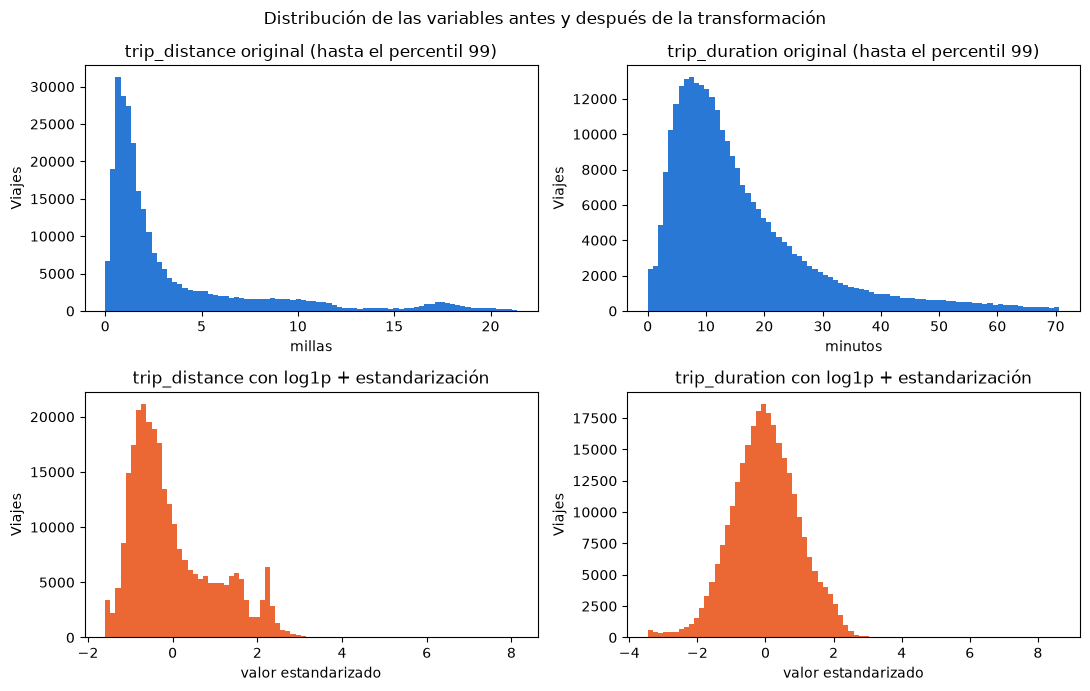

In [4]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = pd.DataFrame(scaler.fit_transform(X_log), columns=X.columns, index=X.index)

print("Variables originales (millas y minutos):")
display(X.describe().round(2))

print("Variables con log1p:")
display(X_log.describe().round(2))

print("Variables con log1p + StandardScaler (media ≈ 0 y desviación estándar ≈ 1):")
display(X_escalado.describe().round(2))

fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for j, col in enumerate(X.columns):
    unidad = "millas" if col == "trip_distance" else "minutos"
    ejes[0, j].hist(X[col], bins=80, range=(0, X[col].quantile(0.99)), color="#2a78d6")
    ejes[0, j].set_title(f"{col} original (hasta el percentil 99)")
    ejes[0, j].set_xlabel(unidad)
    ejes[0, j].set_ylabel("Viajes")
    ejes[1, j].hist(X_escalado[col], bins=80, color="#eb6834")
    ejes[1, j].set_title(f"{col} con log1p + estandarización")
    ejes[1, j].set_xlabel("valor estandarizado")
    ejes[1, j].set_ylabel("Viajes")
fig.suptitle("Distribución de las variables antes y después de la transformación")
fig.tight_layout()
plt.show()

## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

k = 2:  inercia =   227,681.23   silueta = 0.5320


k = 3:  inercia =   137,511.96   silueta = 0.4478


k = 4:  inercia =   100,620.19   silueta = 0.4191


k = 5:  inercia =    79,205.37   silueta = 0.3894


k = 6:  inercia =    66,980.31   silueta = 0.3737

Tabla comparativa:


,k,Inercia,Silueta,Reducción de inercia (%)
0,2,227681.2292,0.5320,NaN
1,3,137511.9588,0.4478,39.6033
2,4,100620.1949,0.4191,26.8280
3,5,79205.3717,0.3894,21.2828
4,6,66980.3104,0.3737,15.4346


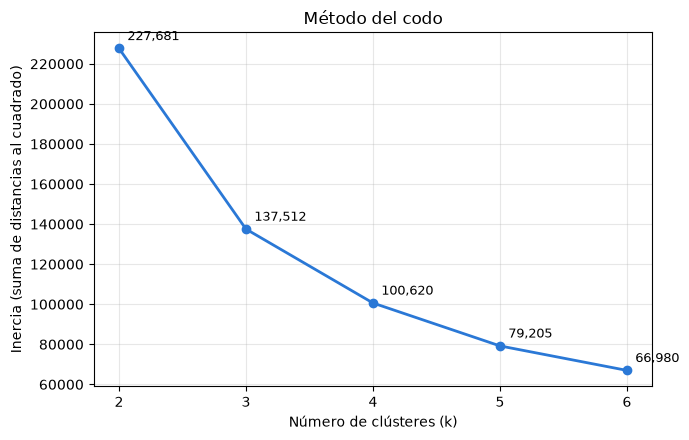

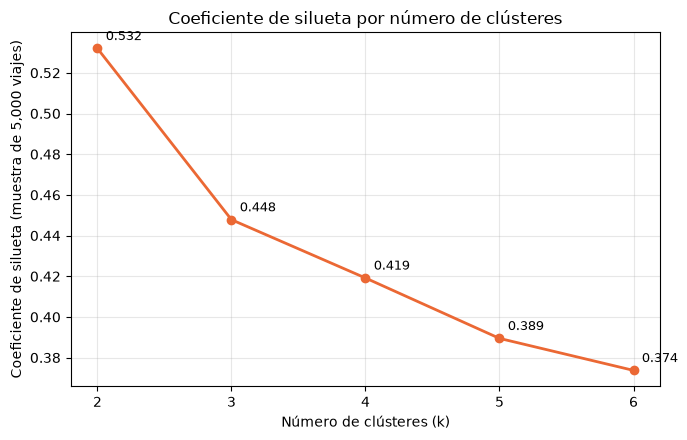

In [5]:
valores_k = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo.fit_predict(X_escalado)
    inercia = modelo.inertia_
    silueta = silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42)
    inercias.append(inercia)
    siluetas.append(silueta)
    print(f"k = {k}:  inercia = {inercia:>12,.2f}   silueta = {silueta:.4f}")

tabla_k = pd.DataFrame({"k": valores_k, "Inercia": inercias, "Silueta": siluetas})
tabla_k["Reducción de inercia (%)"] = -tabla_k["Inercia"].pct_change() * 100
print("\nTabla comparativa:")
display(tabla_k.round(4))

plt.figure(figsize=(7, 4.5))
plt.plot(valores_k, inercias, marker="o", color="#2a78d6", linewidth=2)
for k, inercia in zip(valores_k, inercias):
    plt.annotate(f"{inercia:,.0f}", (k, inercia), xytext=(6, 6), textcoords="offset points", fontsize=9)
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia (suma de distancias al cuadrado)")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4.5))
plt.plot(valores_k, siluetas, marker="o", color="#eb6834", linewidth=2)
for k, silueta in zip(valores_k, siluetas):
    plt.annotate(f"{silueta:.3f}", (k, silueta), xytext=(6, 6), textcoords="offset points", fontsize=9)
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta (muestra de 5,000 viajes)")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

Viajes por clúster:
viajes
0     62395
1    125521
2     94169
Name: count, dtype: int64

Centroides en el espacio log1p + estandarizado:


,trip_distance,trip_duration
C0,1.569,1.214
C1,-0.123,0.186
C2,-0.872,-1.048


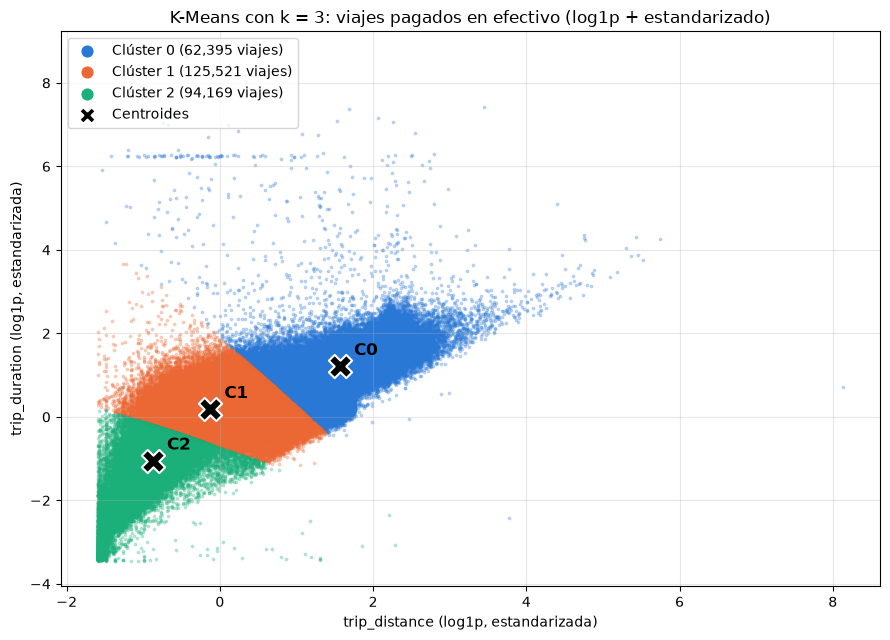

In [6]:
k_final = 3

kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
kmeans_final.fit(X_escalado)

etiquetas = kmeans_final.labels_
centroides = kmeans_final.cluster_centers_

print("Viajes por clúster:")
print(pd.Series(etiquetas, name="viajes").value_counts().sort_index())
print("\nCentroides en el espacio log1p + estandarizado:")
display(pd.DataFrame(centroides, columns=X.columns, index=[f"C{i}" for i in range(k_final)]).round(3))

colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

plt.figure(figsize=(9, 6.5))
for i in range(k_final):
    mascara = etiquetas == i
    plt.scatter(
        X_escalado.loc[mascara, "trip_distance"], X_escalado.loc[mascara, "trip_duration"],
        s=3, alpha=0.25, color=colores[i], label=f"Clúster {i} ({mascara.sum():,} viajes)"
    )

plt.scatter(
    centroides[:, 0], centroides[:, 1],
    marker="X", s=280, c="black", edgecolors="white", linewidths=1.5, zorder=5, label="Centroides"
)
for i, (cx, cy) in enumerate(centroides):
    plt.annotate(f"C{i}", (cx, cy), xytext=(10, 8), textcoords="offset points", fontsize=12, fontweight="bold")

plt.title(f"K-Means con k = {k_final}: viajes pagados en efectivo (log1p + estandarizado)")
plt.xlabel("trip_distance (log1p, estandarizada)")
plt.ylabel("trip_duration (log1p, estandarizada)")
leyenda = plt.legend(loc="upper left")
for h in leyenda.legend_handles:
    h.set_alpha(1)
    h.set_sizes([60])
leyenda.legend_handles[-1].set_sizes([140])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [7]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

tabla_clusters = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("trip_distance", "size"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_min=("trip_duration", "mean"),
    duracion_mediana_min=("trip_duration", "median"),
)
tabla_clusters.insert(1, "porcentaje_viajes", tabla_clusters["cantidad_viajes"] / len(df_resultado) * 100)

print("Estadísticos por clúster (distancia en millas, duración en minutos):")
display(tabla_clusters.round(2))

rangos = df_resultado.groupby("cluster").agg(
    distancia_min=("trip_distance", "min"),
    distancia_max=("trip_distance", "max"),
    duracion_min=("trip_duration", "min"),
    duracion_max=("trip_duration", "max"),
)
print("Rangos por clúster (millas y minutos):")
display(rangos.round(2))

Estadísticos por clúster (distancia en millas, duración en minutos):


,cantidad_viajes,porcentaje_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_min,duracion_mediana_min
cluster,,,,,,
0,62395,22.12,11.55,9.81,39.48,31.40
1,125521,44.50,2.30,1.94,15.43,14.00
2,94169,33.38,0.80,0.76,5.72,5.82


Rangos por clúster (millas y minutos):


,distancia_min,distancia_max,duracion_min,duracion_max
cluster,,,,
0,0.05,1686.49,1.25,8373.67
1,0.01,8.71,4.80,206.45
2,0.01,18.40,0.03,14.22


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**

Elegí k = 3. En la gráfica del codo la inercia baja mucho de k = 2 a k = 3. Pasa de 227,681 a 137,512 y eso es una caída de casi 40 %. Después de 3 la inercia sigue bajando pero cada vez menos. Por eso el codo está en 3. La silueta es más alta con k = 2 con 0.532 pero con dos grupos solo se separan los viajes cortos del resto y se mezclan viajes de 2 millas con viajes de 15. Con k = 3 la silueta queda en 0.448 que todavía es un valor aceptable. Con k = 4, 5 y 6 la silueta sigue bajando y no aparece ningún grupo nuevo que tenga sentido. En la gráfica de dispersión los tres grupos se ven bien separados y cada uno es un tipo de viaje distinto. Por eso k = 3 es la mejor opción.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

El clúster 2 son los viajes cortos. Tiene 94,169 viajes que son el 33 % del total. La distancia media es de 0.80 millas y la mediana de 0.76. La duración media es de 5.72 minutos y la mediana de 5.82. La media y la mediana son casi iguales así que es un grupo muy parejo. Son viajes de unas cuantas cuadras dentro de la misma zona. Le puse el nombre de viajes cortos.

El clúster 1 son los viajes medios. Es el grupo más grande con 125,521 viajes que son el 44 % del total. La distancia media es de 2.30 millas y la mediana de 1.94. La duración media es de 15.43 minutos y la mediana de 14. Es el viaje normal de taxi dentro de la ciudad. Ningún viaje de este grupo pasa de 9 millas. Le puse el nombre de viajes urbanos medios.

El clúster 0 son los viajes largos. Tiene 62,395 viajes que son el 22 % del total. La distancia media es de 11.55 millas y la mediana de 9.81. La duración media es de 39.48 minutos y la mediana de 31.40. Aquí la media es mucho mayor que la mediana porque hay algunos viajes muy largos que suben el promedio. En el histograma de distancias se ve un pico cerca de las 17 millas que coincide con los viajes al aeropuerto. Le puse el nombre de viajes largos y de aeropuerto.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**

El clúster 0 tiene la mayor duración promedio con 39.48 minutos. El clúster 1 tiene 15.43 y el clúster 2 tiene 5.72. También tiene la mayor distancia promedio con 11.55 millas contra 2.30 y 0.80 de los otros dos. Con las medianas pasa lo mismo. Esto tiene sentido porque mientras más lejos va el taxi más tiempo tarda. Por eso en la gráfica los puntos forman una diagonal y el orden de los grupos es el mismo en distancia y en duración.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**

El grupo más numeroso es el clúster 1 con 125,521 viajes que son el 44.5 % de todos los viajes en efectivo. En este grupo predominan distancias de alrededor de 2 millas y duraciones de 14 a 15 minutos. La mediana de distancia es de 1.94 millas y la de duración de 14 minutos. Son los viajes típicos dentro de la ciudad. Si se juntan con los viajes cortos casi 8 de cada 10 viajes en efectivo recorren menos de 4 millas y duran menos de 20 minutos.

---
### Lista de verificación antes de entregar

- [x] Se muestran la carga, exploración, limpieza y filtrado.
- [x] Se utilizaron las **dos variables indicadas**.
- [x] Se aplicaron `log1p` y `StandardScaler`.
- [x] Se calcularon inercia y silueta para `k = 2...6`.
- [x] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [x] Se visualizan los clústeres y sus centroides.
- [x] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [x] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**